# Hebbian Learning and Oja's Rule
This notebook demonstrates basic Hebbian learning and its modification, Oja's rule, which stabilizes the learning process.

## 1. Basic Hebbian Learning
Hebbian learning is often summarized as 'cells that fire together, wire together'. The weight update is proportional to the product of pre- and post-synaptic activity.


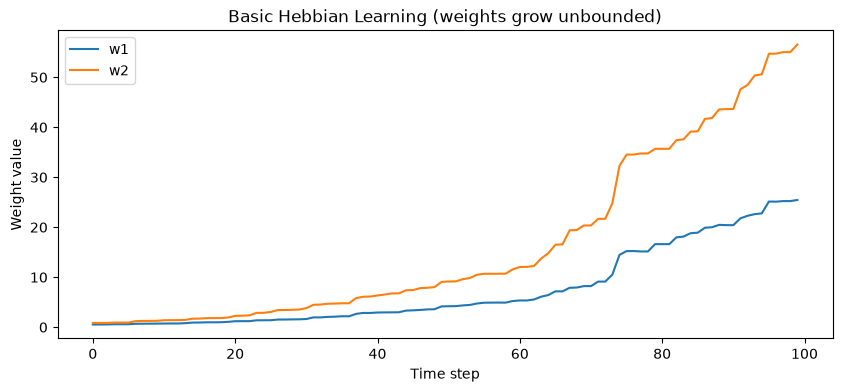

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
np.random.seed(42)
N = 2  # Two inputs
T = 100  # Number of time steps
eta = 0.01  # Learning rate

# Inputs: 2D data points drawn from a Gaussian distribution
X = np.random.randn(N, T)
X[1, :] += 2.0 * X[0, :]  # Introduce correlation

# Initialize weights
w = np.random.randn(N)
w = w / np.linalg.norm(w)

weights_history = []
for t in range(T):
    x = X[:, t]
    y = np.dot(w, x)  # Linear neuron
    # Hebbian update
    w = w + eta * y * x
    weights_history.append(w.copy())

weights_history = np.array(weights_history)

plt.figure(figsize=(10, 4))
plt.plot(weights_history[:, 0], label='w1')
plt.plot(weights_history[:, 1], label='w2')
plt.xlabel('Time step')
plt.ylabel('Weight value')
plt.title('Basic Hebbian Learning (weights grow unbounded)')
plt.legend()
plt.show()


## 2. Oja's Rule
Oja's rule introduces a normalization term that prevents the weights from growing indefinitely, effectively finding the first principal component of the input data.


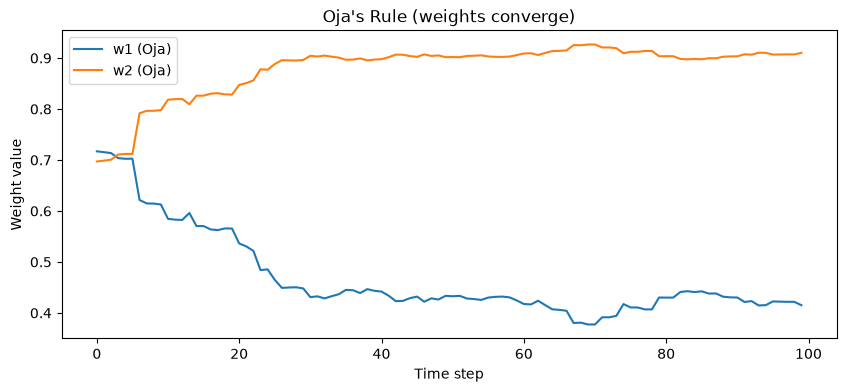

In [2]:
# Oja's rule implementation
w_oja = np.random.randn(N)
w_oja = w_oja / np.linalg.norm(w_oja)

weights_oja_history = []
for t in range(T):
    x = X[:, t]
    y = np.dot(w_oja, x)
    # Oja's update
    w_oja = w_oja + eta * y * (x - y * w_oja)
    weights_oja_history.append(w_oja.copy())

weights_oja_history = np.array(weights_oja_history)

plt.figure(figsize=(10, 4))
plt.plot(weights_oja_history[:, 0], label='w1 (Oja)')
plt.plot(weights_oja_history[:, 1], label='w2 (Oja)')
plt.xlabel('Time step')
plt.ylabel('Weight value')
plt.title("Oja's Rule (weights converge)")
plt.legend()
plt.show()
